In [1]:
import csv
import numpy as np

def read_csv_numeric(path):
    # 1) read header for the name→index mapping
    with open(path, newline='', encoding='utf-8') as f:
        reader = csv.reader(f)
        header = next(reader)
    col_idx = {name: i for i, name in enumerate(header)}

    # 2) load the rest as a 2D float array (missing -> NaN)
    # reopen so the file pointer is at the top again
    data = np.genfromtxt(
        path,
        delimiter=",",
        skip_header=1,
        dtype=float,
        missing_values=["", "NA", "NaN"],
        filling_values=np.nan
    )
    # If the CSV has only one data row, genfromtxt returns 1D; force 2D
    if data.ndim == 1:
        data = data.reshape(1, -1)

    return col_idx, data

In [2]:
x_indices, x_data = read_csv_numeric("../dataset/x_train.csv")
y_indices, y_data = read_csv_numeric("../dataset/y_train.csv")

In [3]:
# we select interesting columns and clean the dataset

import matplotlib.pyplot as plt

interesting_columns = ["QLACTLM2","_MISFRTN","_FRUITEX","_RFSEAT2","DRNKANY5","WTKG3","TRNSGNDR","FLUSHOT6","ORNGDAY_","PAFREQ2_","INCOME2","_VEGESUM","CHECKUP1","_VEGETEX","MAXVO2_","CHCOCNCR","_MINAC11","HIVTST6","VETERAN3","SEX","DRNK3GE5","LMTJOIN3","DIFFALON","_RACE_G1","_BMI5","BPHIGH4","FC60_","CHOLCHK","PADUR1_","MEDCOST","_LMTACT1","_SMOKER3","METVL11_","PADUR2_","FRUTDA1_","STRFREQ_","PHYSHLTH","GENHLTH","_PASTRNG","PERSDOC2","POORHLTH","_LMTSCL1","DECIDE","_PAINDX1","_MINAC21","_MISVEGN","VEGEDA1_","ADDEPEV2","CHCSCNCR","BPMEDS","HTM4","DIFFDRES","SXORIENT","PAMIN11_","_DRNKWEK","ALCDAY5","_PACAT1","EXERANY2","DIFFWALK","USEEQUIP","MENTHLTH","EMPLOY1","EXRACT11","TOLDHI2","AVEDRNK2","PAVIG21_","CHCKIDNY","_FRUTSUM","PA1MIN_","_ASTHMS1","DROCDY3_","HAVARTH3","_LMTWRK1","FLSHTMY2","PAVIG11_","PAMIN21_","GRENDAY_","ARTHDIS2","METVL21_","ARTHSOCL","PAMISS1_","_RFHLTH","BLIND","FRUIT1","_TOTINDA","JOINPAIN","DIABETE3","_PASTAE1","_MRACE1","_PAREC1","SMOKDAY2","SMOKE100","MSCODE","PA1VIGM_","BEANDAY_","_AGE80","USENOW3","BLOODCHO","PNEUVAC3","PAFREQ1_","CVDSTRK3","CHCCOPD1","EXRACT21","_CASTHM1","_AIDTST3","MAXDRNKS"

                        ]

# 6-digit: DK/Ref codes like 777777 / 999999
six_digit = [
    'FLSHTMY2',
    'HIVTSTD3',
]

# 5-digit: DK/Ref codes like 99999 (e.g., WTKG3)
five_digit = [
    'PA1VIGM_',
    'PAFREQ2_',
    'WTKG3',
]

# 4-digit: DK/Ref codes like 7777 / 9999 (e.g., WEIGHT2)
four_digit = [
    'AVEDRNK2',
    'BEANDAY_',
    'FRUTDA1_',
    'FTJUDA1_',
    'GRENDAY_',
    'HEIGHT3',
    'ORNGDAY_',
    'VEGEDA1_',
    'WEIGHT2',
    '_BMI5',
    '_BMI5CAT',
    '_RFBMI5',
]

# 3-digit: DK/Ref codes like 777 / 999 (e.g., ALCDAY5)
triple_digit = [
    'ALCDAY5',
    'ASACTLIM',
    'ASNOSLEP',
    'BLDSUGAR',
    'CDHELP',
    'DRNK3GE5',
    'DRNKANY5',
    'EXERHMM1',
    'EXERHMM2',
    'EXEROFT1',
    'EXEROFT2',
    'FEETCHK2',
    'FRUIT1',
    'FRUITJU1',
    'FVBEANS',
    'FVGREEN',
    'FVORANG',
    'LONGWTCH',
    'MAXDRNKS',
    'STRENGTH',
    'VEGETAB1',
    '_LMTSCL1',
    '_RFBING5',
]

# 2-digit: DK/Ref codes like 77 / 99 (e.g., DRNK3GE5)
double_digit = [
    'ADANXEV','ADDOWN','ADEAT1','ADENERGY','ADFAIL','ADMOVE','ADPLEASR','ADSLEEP','ADTHINK','ARTHSOCL',
    'ARTTODAY','ASINHALR','ASRCHKUP','ASTHMAGE','CAREGIV1','CASTHDX2','CDDISCUS','CDSOCIAL','CHKHEMO3','CRGVEXPT',
    'CRGVHOUS','CRGVPERS','CRGVPRB1','CRGVREL1','CVDINFR4','DIABAGE2','DIABETE3','DOCTDIAB','EMTSUPRT','EXRACT11',
    'EXRACT21','FC60_','FEETCHK','HAREHAB1','HHADULT','HOWLONG','HPVADVC2','IMFVPLAC','INCOME2','JOINPAIN',
    'LASTSIG3','LASTSMK2','LENGEXAM','LSTBLDS3','MAXVO2_','MENTHLTH','PAFREQ1_','PERSDOC2','PHYSHLTH','POORHLTH',
    'PSATIME','RDUCHART','SCNTLWK1','SCNTWRK1','SXORIENT','TRNSGNDR','VETERAN3','VINOCRE2','WHRTST10','_ASTHMS1',
    '_CRACE1','_DRDXAR1','_EDUCAG','_PNEUMO2','_PRACE1','_RACE','_RACE_G1','_WT2RAKE',
]

# 1-digit: DK/Ref codes like 7 / 9 (e.g., EXERANY2)
single_digit = [
    'ADDEPEV2','ARTHDIS2','ARTHEDU','ARTHEXER','ARTHWGT','ASATTACK','ASDRVIST','ASERVIST','ASPUNSAF','ASTHMA3','ASTHMED3','ASYMPTOM',
    'BLDSTOOL','BLIND','BLOODCHO','BPHIGH4','CASTHNO2','CDASSIST','CDHOUSE','CHCCOPD1','CHCKIDNY','CHECKUP1','CHOLCHK','CIMEMLOS',
    'CPDEMO1','CRGVHRS1','CRGVMST2','DECIDE','DIABEDU','DIABEYE','DIFFALON','DRADVISE','EDUCA','EXERANY2','EYEEXAM','FLUSHOT6',
    'HADHYST2','HADMAM','HADPAP2','HADSGCO1','HADSIGM3','HAVARTH3','HIVTST6','HLTHPLN1','HPVADSHT','HPVTEST','LANDLINE','LMTJOIN3',
    'MEDCOST','MISTMNT','NUMHHOL2','PCPSAAD2','PCPSADE1','PCPSADI1','PCPSARE1','PDIABTST','PNEUVAC3','PREDIAB1','PROFEXAM','QLACTLM2',
    'RENTHOM1','SCNTLPAD','SCNTMEL1','SCNTMNY1','SCNTPAID','SEATBELT','SMOKE100','STOPSMK2','STREHAB1','STRFREQ_','TETANUS','TOLDHI2',
    'USEEQUIP','USENOW3','VICTRCT4','VIDFCLT2','VIEYEXM2','VIGLUMA2','VIMACDG2','VIPRFVS2','VIREDIF3','WTCHSALT','_CHOLCHK','_HCVU651',
    '_LLCPWT','_LMTACT1','_MICHD','_PA150R2','_PA30021','_PA300R2','_PASTRNG','_RACEG21','_RFCHOL','_RFDRHV5','_RFHYPE5','_RFSEAT2',
    '_SMOKER3','_TOTINDA','_VEGESUM',
]

# No explicit DK/Ref "7…/9…" code in that variable’s own table
no_dk_rf = [
    'ACTIN11_','ACTIN21_','ASTHNOW','BPMEDS','CADULT','CCLGHOUS','CELLFON2','CELLFON3','CHCOCNCR','CHCSCNCR',
    'CHILDREN','COLGHOUS','CRGVLNG1','CSTATE','CTELENUM','CTELNUM1','CVDASPRN','CVDCRHD4','CVDSTRK3','DIFFDRES',
    'DIFFWALK','DISPCODE','DROCDY3_','EMPLOY1','EXACTOT1','EXACTOT2','EXRACT11','EXRACT21','FMONTH','GENHLTH',
    'HPLSTTST','HTIN4','HTM4','IDATE','IDAY','IMONTH','INSULIN','INTERNET','IYEAR','LADULT',
    'LASTPAP2','LSATISFY','MARITAL','METVL11_','METVL21_','MSCODE','NUMADULT','NUMMEN','NUMPHON2','NUMWOMEN',
    'PA1MIN_','PADUR1_','PADUR2_','PAINACT2','PAMIN11_','PAMIN21_','PAMISS1_','PAVIG11_','PAVIG21_','PCDMDECN',
    'PCPSARS1','PREGNANT','PSATEST1','PVTRESD1','PVTRESD2','QLHLTH2','QLMENTL2','QLSTRES2','QSTLANG','QSTVER',
    'RCSGENDR','RCSRLTN2','RDUCSTRK','RLIVPAIN','SEQNO','SEX','SHINGLE2','SMOKDAY2','STATERES','VIINSUR2',
    '_AGE65YR','_AGE80','_AGEG5YR','_AGE_G','_AIDTST3','_CASTHM1','_CHISPNC','_CHLDCNT','_CLLCPWT','_CPRACE',
    '_DRNKWEK','_DUALCOR','_DUALUSE','_FLSHOT6','_FRT16','_FRTLT1','_FRTRESP','_FRUITEX','_FRUTSUM','_HISPANC',
    '_INCOMG','_LMTWRK1','_LTASTH1','_MINAC11','_MINAC21','_MISFRTN','_MISVEGN','_MRACE1','_PACAT1','_PAINDX1',
    '_PAREC1','_PASTAE1','_PSU','_RACEGR3','_RAWRAKE','_RFHLTH','_RFSEAT3','_RFSMOK3','_STATE','_STRWT',
    '_STSTR','_VEG23','_VEGETEX','_VEGLT1','_VEGRESP',
]


for c in interesting_columns:
    if c in single_digit:
        x_data[x_data[:, x_indices[c]] == 7, x_indices[c]] = np.nan
        x_data[x_data[:, x_indices[c]] == 8, x_indices[c]] = 0
        x_data[x_data[:, x_indices[c]] == 9, x_indices[c]] = np.nan
    elif c in double_digit:
        x_data[x_data[:, x_indices[c]] == 77, x_indices[c]] = np.nan
        x_data[x_data[:, x_indices[c]] == 88, x_indices[c]] = 0
        x_data[x_data[:, x_indices[c]] == 99, x_indices[c]] = np.nan
    elif c in triple_digit:
        x_data[x_data[:, x_indices[c]] == 777, x_indices[c]] = np.nan
        x_data[x_data[:, x_indices[c]] == 888, x_indices[c]] = 0
        x_data[x_data[:, x_indices[c]] == 999, x_indices[c]] = np.nan
    elif c in four_digit:
        x_data[x_data[:, x_indices[c]] == 7777, x_indices[c]] = np.nan
        x_data[x_data[:, x_indices[c]] == 8888, x_indices[c]] = 0
        x_data[x_data[:, x_indices[c]] == 9999, x_indices[c]] = np.nan
    elif c in five_digit:
        x_data[x_data[:, x_indices[c]] == 77777, x_indices[c]] = np.nan
        x_data[x_data[:, x_indices[c]] == 88888, x_indices[c]] = 0
        x_data[x_data[:, x_indices[c]] == 99999, x_indices[c]] = np.nan
    elif c in six_digit:
        x_data[x_data[:, x_indices[c]] == 777777, x_indices[c]] = np.nan
        x_data[x_data[:, x_indices[c]] == 888888, x_indices[c]] = 0
        x_data[x_data[:, x_indices[c]] == 999999, x_indices[c]] = np.nan
    else:
        if c not in no_dk_rf: 
            raise Exception("Not in any group", c)
    
x_data[x_data[:, x_indices["WEIGHT2"]] <= 1000, x_indices["WEIGHT2"]] = x_data[x_data[:, x_indices["WEIGHT2"]] <= 1000, x_indices["WEIGHT2"]] * 0.453592
x_data[x_data[:, x_indices["WEIGHT2"]] >= 9000, x_indices["WEIGHT2"]] = x_data[x_data[:, x_indices["WEIGHT2"]] >= 9000, x_indices["WEIGHT2"]] - 9000
x_data[x_data[:, x_indices["HEIGHT3"]] <= 1000, x_indices["HEIGHT3"]] = ((x_data[x_data[:, x_indices["HEIGHT3"]] <= 1000, x_indices["HEIGHT3"]]) // 100) * 30.48 + ((x_data[x_data[:, x_indices["HEIGHT3"]] <= 1000, x_indices["HEIGHT3"]]) % 100) * 2.54
x_data[x_data[:, x_indices["HEIGHT3"]] >= 9000, x_indices["HEIGHT3"]] = x_data[x_data[:, x_indices["HEIGHT3"]] >= 9000, x_indices["HEIGHT3"]] - 9000
x_data[x_data[:, x_indices["WEIGHT2"]] > 200, x_indices["WEIGHT2"]] = np.nan

In [4]:
# --- Keep only the columns of interest ---
x_data_interested = x_data[:, [x_indices[col] for col in interesting_columns]]
x_indices_interested = {col: i for i, col in enumerate(interesting_columns)}

# --- Drop columns that are all NaN ---
valid_cols = ~np.isnan(x_data_interested).all(axis=0)
x_data_interested = x_data_interested[:, valid_cols]
interesting_columns = [col for col, keep in zip(interesting_columns, valid_cols) if keep]
x_indices_interested = {col: i for i, col in enumerate(interesting_columns)}

# --- Impute remaining NaNs with column mean ---
col_mean = np.nanmean(x_data_interested, axis=0)
inds = np.where(np.isnan(x_data_interested))
x_data_interested[inds] = np.take(col_mean, inds[1])

# --- Standardize once ---
x_data_interested = (x_data_interested - np.mean(x_data_interested, axis=0)) / np.std(x_data_interested, axis=0)

# --- Prepare y ---
y = y_data[:,1].copy()
y[np.isnan(y)] = np.nanmean(y)
y = (y + 1) / 2  # convert -1,1 → 0,1
y = y.reshape(-1,1)

# --- Checks ---
print("Unique labels:", np.unique(y))
print("Any NaN in features?", np.any(np.isnan(x_data_interested)))
print("Min std across features:", np.min(np.std(x_data_interested, axis=0)))
print("Label distribution (mean):", np.mean(y))

Unique labels: [0. 1.]
Any NaN in features? False
Min std across features: 0.9999999999999998
Label distribution (mean): 0.08830207079403295


In [5]:
def logistic_regression(y, tx, initial_w, max_iters, gamma, tol=None):
    w = initial_w.copy()
    losses = []
    ws = []

    for n_iter in range(max_iters):
        grad = calculate_gradient(y, tx, w)
        w_new = w - gamma * grad
        loss = calculate_loss(y, tx, w_new)

        ws.append(w_new.copy())
        losses.append(loss)

        # Early stopping if tolerance specified
        if tol is not None and n_iter > 5:
            rel_change = abs(losses[-2] - losses[-1]) / (abs(losses[-2]) + 1e-10)
            if rel_change < tol:
                print(f"Stopping early at iter {n_iter} (Δloss_rel < tol)")
                break

        w = w_new

    return w, np.array(losses), ws

def sigmoid(t):
    out = np.empty_like(t, dtype=np.float64)
    pos = t >= 0
    neg = ~pos
    out[pos] = 1 / (1 + np.exp(-t[pos]))
    out[neg] = np.exp(t[neg]) / (1 + np.exp(t[neg]))
    return out


def calculate_loss(y, tx, w):
    """compute the cost by negative log likelihood.

    Args:
        y:  shape=(N, 1)
        tx: shape=(N, D)
        w:  shape=(D, 1)

    Returns:
        a non-negative loss

    >>> y = np.c_[[0., 1.]]
    >>> tx = np.arange(4).reshape(2, 2)
    >>> w = np.c_[[2., 3.]]
    >>> round(calculate_loss(y, tx, w), 8)
    1.52429481
    """
    assert y.shape[0] == tx.shape[0]
    assert tx.shape[1] == w.shape[0]

    n = y.shape[0]
    pred = sigmoid(tx @ w)

    # optional clip for numerical stability
    eps = 1e-15
    pred = np.clip(pred, eps, 1 - eps)

    L = -(1 / n) * np.sum(y * np.log(pred) + (1 - y) * np.log(1 - pred))
    return float(L)


def calculate_gradient(y, tx, w):
    """compute the gradient of loss.

    Args:
        y:  shape=(N, 1)
        tx: shape=(N, D)
        w:  shape=(D, 1)

    Returns:
        a vector of shape (D, 1)

    >>> np.set_printoptions(8)
    >>> y = np.c_[[0., 1.]]
    >>> tx = np.arange(6).reshape(2, 3)
    >>> w = np.array([[0.1], [0.2], [0.3]])
    >>> calculate_gradient(y, tx, w)
    array([[-0.10370763],
           [ 0.2067104 ],
           [ 0.51712843]])
    """
    grad = tx.T @ (sigmoid(tx @ w) - y) / y.shape[0]
    return grad


def reg_logistic_regression(y, tx, lambda_, initial_w, max_iters, gamma, tol=None):
    w = initial_w.copy()
    losses = []
    ws = []

    for n_iter in range(max_iters):
        loss, grad = penalized_logistic_regression(y, tx, w, lambda_)
        w_new = w - gamma * grad
        loss_new = calculate_loss(y, tx, w_new)

        ws.append(w_new.copy())
        losses.append(loss_new)

        if tol is not None and n_iter > 5:
            rel_change = abs(losses[-2] - losses[-1]) / (abs(losses[-2]) + 1e-10)
            if rel_change < tol:
                print(f"Stopping early at iter {n_iter} (Δloss_rel < tol)")
                break

        w = w_new

    return w, np.array(losses), ws


def penalized_logistic_regression(y, tx, w, lambda_):
    """return the loss and gradient.

    Args:
        y:  shape=(N, 1)
        tx: shape=(N, D)
        w:  shape=(D, 1)
        lambda_: scalar

    Returns:
        loss: scalar number
        gradient: shape=(D, 1)

    >>> y = np.c_[[0., 1.]]
    >>> tx = np.arange(6).reshape(2, 3)
    >>> w = np.array([[0.1], [0.2], [0.3]])
    >>> lambda_ = 0.1
    >>> loss, gradient = penalized_logistic_regression(y, tx, w, lambda_)
    >>> round(loss, 8)
    0.62137268
    >>> gradient
    array([[-0.08370763],
           [ 0.2467104 ],
           [ 0.57712843]])
    """
    loss = calculate_loss(y, tx, w)
    gradient = tx.T @ (sigmoid(tx @ w) - y) / y.shape[0] + 2 * lambda_ * w
    # hessian = calculate_hessian(y, tx, w)
    return float(loss), gradient


def gptversion_logistic_regression(y, tx, lambda_, initial_w, max_iters, gamma, tol=None):
    w = initial_w.copy()
    losses = []
    ws = []

    for n_iter in range(max_iters):
        pos_weight = 1 / np.mean(y)
        neg_weight = 1 / (1 - np.mean(y))
        weights = y * pos_weight + (1 - y) * neg_weight
        grad = weighted_logistic_gradient(y, tx, w, weights)
        w_new = w - gamma * grad
        loss = weighted_logistic_loss(y,tx,w,weights)

        ws.append(w_new.copy())
        losses.append(loss)

        # Early stopping if tolerance specified
        if tol is not None and n_iter > 5:
            rel_change = abs(losses[-2] - losses[-1]) / (abs(losses[-2]) + 1e-10)
            if rel_change < tol:
                print(f"Stopping early at iter {n_iter} (Δloss_rel < tol)")
                break

        w = w_new

    return w, np.array(losses), ws

def weighted_logistic_loss(y, tx, w, sample_weights):
    pred = sigmoid(tx @ w)
    pred = np.clip(pred, 1e-15, 1-1e-15)
    loss = -np.sum(sample_weights * (y * np.log(pred) + (1 - y) * np.log(1 - pred))) / np.sum(sample_weights)
    return loss

def weighted_logistic_gradient(y, tx, w, sample_weights):
    pred = sigmoid(tx @ w)
    grad = (tx.T @ (sample_weights * (pred - y))) / np.sum(sample_weights)
    return grad

In [6]:
import matplotlib.pyplot as plt
import numpy as np

def run_experiment(y, tx, col_names, kind="logistic", 
                   gamma=0.01, lambda_=0.0, max_iters=1000, 
                   tol=None, w_init=None, verbose=True):
    """
    Run (regularized) logistic regression and visualize results.

    Args:
        y: np.ndarray, shape (N, 1)
        tx: np.ndarray, shape (N, D)
        col_names: list of feature names
        kind: "logistic" or "reg_logistic"
        gamma: learning rate
        lambda_: regularization strength
        max_iters: number of iterations
        tol: optional early stopping tolerance
        w_init: optional initial weight vector
        verbose: if True, prints info

    Returns:
        final_w, final_loss
    """
    n_features = tx.shape[1]
    if w_init is None:
        w_init = np.zeros((n_features, 1))

    if kind == "gpt_logistic":
        w, losses, ws = gptversion_logistic_regression(y, tx, lambda_, w_init, max_iters, gamma, tol)
    elif kind == "logistic":
        w, losses, ws = logistic_regression(y, tx, w_init, max_iters, gamma, tol)
    elif kind == "reg_logistic":
        w, losses, ws = reg_logistic_regression(y, tx, lambda_, w_init, max_iters, gamma, tol)
    else:
        raise ValueError("kind must be 'logistic' or 'reg_logistic'")

    # Plot loss curve
    plt.figure(figsize=(6, 4))
    plt.plot(losses, marker='o')
    plt.title(f"{kind.capitalize()} Regression\nγ={gamma}, λ={lambda_}, iters={len(losses)}")
    plt.xlabel("Iteration")
    plt.ylabel("Loss")
    plt.grid(True)
    plt.show()

    # Display readable summary
    if verbose:
        print(f"\nFinal loss: {losses[-1]:.6f}")
        print(f"Iterations: {len(losses)}")
        print("\nTop 20 features by |weight|:\n")
        top_idx = np.argsort(np.abs(w.flatten()))[::-1][:20]
        for i in top_idx:
            print(f"{col_names[i]:25s}  w = {w[i,0]:.5f}")

    return w, losses[-1]

In [ ]:
# --- Remove all-NaN columns ---
valid_cols = ~np.isnan(x_data).all(axis=0)
x_data_general = x_data[:, valid_cols]
total_columns = [col for col, keep in zip(list(x_indices.keys()), valid_cols) if keep]

# --- Remove constant columns (std == 0) ---
stds = np.nanstd(x_data_general, axis=0)
non_const_cols = stds > 0
x_data_general = x_data_general[:, non_const_cols]
total_columns = [col for col, keep in zip(total_columns, non_const_cols) if keep]

# --- Replace NaNs with column means ---
col_mean = np.nanmean(x_data_general, axis=0)
inds = np.where(np.isnan(x_data_general))
x_data_general[inds] = np.take(col_mean, inds[1])

# --- Standardize safely ---
x_data_general = (x_data_general - np.mean(x_data_general, axis=0)) / np.std(x_data_general, axis=0)

# --- Rebuild index mapping ---
x_indices = {col: i for i, col in enumerate(total_columns)}


# --- Prepare y ---
y = y_data[:,1].copy()
y[np.isnan(y)] = np.nanmean(y)
y = (y + 1) / 2  # convert -1,1 → 0,1
y = y.reshape(-1,1)

w3, loss3 = run_experiment(y, x_data_general, total_columns, 
                          kind="gpt_logistic", gamma=0.01, 
                            max_iters=300, lambda_=0, tol=1e-4)

In [ ]:
col_names = interesting_columns
tx = x_data_interested
final_y = y

# Example runs
#w1, loss1 = run_experiment(final_y, tx, col_names, 
                           #kind="logistic", gamma=0.1, 
                           #max_iters=100)

#w2, loss2 = run_experiment(final_y, tx, col_names, 
#                          kind="reg_logistic", gamma=0.1, 
#                         lambda_=0, max_iters=300, tol=1e-4)
w3, loss3 = run_experiment(final_y, tx, col_names, 
                          kind="gpt_logistic", gamma=0.1, 
                            max_iters=300, lambda_=2, tol=1e-4)

In [ ]:
print(f"\nFinal loss: {loss3:.6f}")
print("Weights:")
for c, val in zip(col_names, w3.flatten()):
    print(f"{c:20s}: {val: .5f}")


In [7]:
def subset_run(x_data, y, x_indices, subset_cols, 
               kind="logistic", gamma=0.01, lambda_=0.0, 
               max_iters=200, tol=None):
    """
    Run (regularized) logistic regression only on a subset of variables.
    """
    cols_idx = [x_indices[c] for c in subset_cols]
    tx_sub = x_data[:, cols_idx]
    col_names = subset_cols
    w_init = np.zeros((tx_sub.shape[1], 1))

    if kind == "gpt_logistic":
        w, losses, _ = gptversion_logistic_regression(y, tx_sub, lambda_, w_init, max_iters, gamma, tol)
    elif kind == "logistic":
        w, losses, _ = logistic_regression(y, tx_sub, w_init, max_iters, gamma, tol)
    else:
        w, losses, _ = reg_logistic_regression(y, tx_sub, lambda_, w_init, max_iters, gamma, tol)

    plt.plot(losses)
    plt.title(f"{kind} regression on {len(subset_cols)} vars")
    plt.xlabel("Iteration")
    plt.ylabel("Loss")
    plt.grid(True)
    plt.show()

    print(f"\nFinal loss: {losses[-1]:.6f}")
    print("Weights:")
    for c, val in zip(col_names, w.flatten()):
        print(f"{c:20s}: {val: .5f}")

    return w, losses


Stopping early at iter 27 (Δloss_rel < tol)


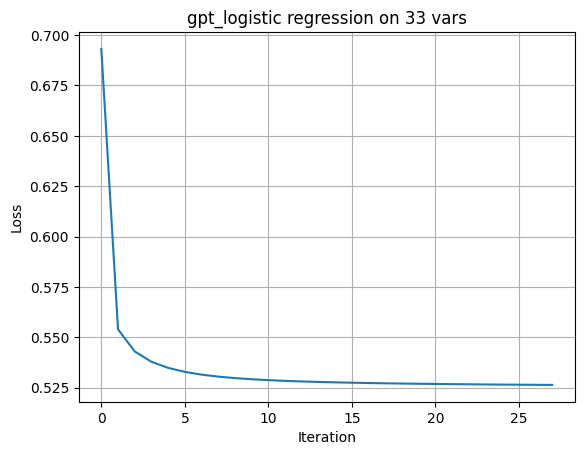


Final loss: 0.526384
Weights:
_AGE80              :  0.31786
BPHIGH4             : -0.21859
GENHLTH             :  0.23189
TOLDHI2             : -0.20569
EMPLOY1             :  0.11815
PNEUVAC3            : -0.12076
SEX                 : -0.22005
CHCCOPD1            : -0.14067
DIABETE3            : -0.09054
_RFHLTH             :  0.05648
VETERAN3            : -0.07181
CHCKIDNY            : -0.09496
CHOLCHK             : -0.09501
SMOKE100            : -0.06887
QLACTLM2            : -0.05496
USEEQUIP            : -0.05292
BLOODCHO            : -0.09424
HAVARTH3            : -0.03693
CVDSTRK3            : -0.06831
PHYSHLTH            :  0.03968
BPMEDS              : -0.05402
INCOME2             : -0.05718
DRNK3GE5            :  0.02691
MEDCOST             : -0.04272
_LMTACT1            : -0.00599
_SMOKER3            : -0.03834
CHCSCNCR            : -0.03278
HTM4                :  0.02958
ALCDAY5             : -0.05552
DIFFWALK            : -0.02273
BLIND               : -0.04926
SMOKDAY2

In [8]:
subset = ["_AGE80",
"BPHIGH4",
"GENHLTH",
"TOLDHI2",
"EMPLOY1",
"PNEUVAC3",
"SEX",
"CHCCOPD1",
"DIABETE3",
"_RFHLTH",
"VETERAN3",
"CHCKIDNY",
"CHOLCHK",
"SMOKE100",
"QLACTLM2",
"USEEQUIP",
"BLOODCHO",
"HAVARTH3",
"CVDSTRK3",
"PHYSHLTH",
"BPMEDS",
"INCOME2",
"DRNK3GE5",
"MEDCOST",
"_LMTACT1",
"_SMOKER3",
"CHCSCNCR",
"HTM4",
"ALCDAY5",
"DIFFWALK",
"BLIND",
"SMOKDAY2",
"_BMI5"
]


w, losses = subset_run(x_data_interested, y, x_indices_interested, subset,
                       kind="gpt_logistic",
                       gamma=0.5, lambda_=0, max_iters=200, tol=1e-4)


In [10]:
x_data_interested = x_data_interested[:, [x_indices_interested[col] for col in subset]]

In [11]:
print(x_data_interested.shape)

(328135, 33)


In [11]:
# Remove fully empty columns
valid_cols = ~np.isnan(x_data).all(axis=0)
x_data = x_data[:, valid_cols]
total_columns = [col for col, keep in zip(list(x_indices.keys()), valid_cols) if keep]
x_indices = {col: i for i, col in enumerate(total_columns)}

# --- Step 1: Impute NaNs before computing mean/std ---
col_mean = np.nanmean(x_data, axis=0)
inds = np.where(np.isnan(x_data))
x_data[inds] = np.take(col_mean, inds[1])

# --- Step 2: Now compute true means/stds safely ---
orig_means = np.mean(x_data, axis=0)
orig_stds = np.std(x_data, axis=0)

# --- Step 4: Denormalize when needed ---
x_data_denorm = x_data_interested * orig_stds[[x_indices[c] for c in subset]] + orig_means[[x_indices[c] for c in subset]]


In [12]:
import os
boxplot_dir = "boxplots_after_logreg"
os.makedirs(boxplot_dir, exist_ok=True)

colors = ["#115B85", "#117215", "#DBFC07"]  # blue, green, yellow

for i, col_name in enumerate(subset):
    data = x_data_denorm[:, i].astype(float)
    mask_not_nan = ~np.isnan(data)
    data_general = data[mask_not_nan]

    data_neg1 = data[(y_data[:, 1] == -1) & mask_not_nan]
    data_pos1 = data[(y_data[:, 1] == 1) & mask_not_nan]

    if len(data_general) == 0:
        print(f"Skipping {col_name} due to no valid data")
        continue

    plt.figure(figsize=(8, 6))
    bplot = plt.boxplot(
        [data_general, data_neg1, data_pos1],
        tick_labels=["All", "y=-1", "y=1"],
        showfliers=False,
        patch_artist=True
    )

    for patch, color in zip(bplot['boxes'], colors):
        patch.set_facecolor(color)
        patch.set_alpha(0.7)

    plt.title(col_name, fontsize=13, weight='bold')
    plt.ylabel("Value", fontsize=12)
    plt.grid(axis="y", linestyle="--", alpha=0.5)
    plt.tight_layout()
    plt.savefig(os.path.join(boxplot_dir, f"{col_name}.png"))
    plt.close()


In [15]:
continuous_features = []
categorical_features = []

n_rows = x_data_denorm.shape[0]

for idx, feature_name in enumerate(subset):
    col = x_data_denorm[:, idx].astype(float)
    col = col[~np.isnan(col)]
    unique_vals = np.unique(col)
    
    n_unique = len(unique_vals)
    frac_unique = n_unique / n_rows
    is_integer_like = np.all(np.isclose(unique_vals % 1, 0, atol=1e-6))
    value_range = np.nanmax(col) - np.nanmin(col)
    
    # --- Improved heuristic ---
    if (
        (n_unique <= 10 and is_integer_like)  # e.g. yes/no or small categories
        or (frac_unique < 0.02 and n_unique < 25)  # very few categories vs data size
        or (value_range <= 10 and is_integer_like)  # ordinal/coded scales (like 1–5 Likert)
    ):
        categorical_features.append(feature_name)
    else:
        continuous_features.append(feature_name)

print(f"Detected {len(categorical_features)} categorical and {len(continuous_features)} continuous features.")


Detected 27 categorical and 6 continuous features.


In [17]:
print(categorical_features)
print(continuous_features)

['BPHIGH4', 'GENHLTH', 'TOLDHI2', 'EMPLOY1', 'PNEUVAC3', 'SEX', 'CHCCOPD1', 'DIABETE3', '_RFHLTH', 'VETERAN3', 'CHCKIDNY', 'CHOLCHK', 'SMOKE100', 'QLACTLM2', 'USEEQUIP', 'BLOODCHO', 'HAVARTH3', 'CVDSTRK3', 'BPMEDS', 'INCOME2', 'MEDCOST', '_LMTACT1', '_SMOKER3', 'CHCSCNCR', 'DIFFWALK', 'BLIND', 'SMOKDAY2']
['_AGE80', 'PHYSHLTH', 'DRNK3GE5', 'HTM4', 'ALCDAY5', '_BMI5']


In [21]:
import os
import numpy as np
import matplotlib.pyplot as plt

# Output folder
hist_relfreq_dir = "histograms_after_logreg"
os.makedirs(hist_relfreq_dir, exist_ok=True)

for i, col_name in enumerate(subset):
    col = x_data_denorm[:, i].astype(float)

    # Build masks and subsets
    mask_valid = ~np.isnan(col)
    mask_neg1 = (y_data[:, 1] == -1) & mask_valid
    mask_pos1 = (y_data[:, 1] == 1) & mask_valid

    data_neg1 = col[mask_neg1]
    data_pos1 = col[mask_pos1]

    fig, axes = plt.subplots(2, 1, figsize=(8, 10))

    # ---------- CATEGORICAL ----------
    if col_name in categorical_features:
        bins = np.unique(np.concatenate([data_neg1, data_pos1]))
        for val in bins:
            axes[0].bar(val, np.sum(data_neg1 == val) / len(data_neg1), 
                    width=1, color='blue', alpha=0.6, edgecolor='black', label='y=-1' if val == bins[0] else "")
            axes[0].bar(val, np.sum(data_pos1 == val) / len(data_pos1), 
                    width=1, color='red', alpha=0.6, edgecolor='black', label='y=1' if val == bins[0] else "")

        axes[0].set_xticks(bins)
        for val in bins:
            axes[1].bar(val, np.sum(data_neg1 == val), 
                    width=1, color='blue', alpha=0.6, edgecolor='black', label='y=-1' if val == bins[0] else "")
            axes[1].bar(val, np.sum(data_pos1 == val), 
                    width=1, color='red', alpha=0.6, edgecolor='black', label='y=1' if val == bins[0] else "")

        axes[1].set_xticks(bins)
    else:
        bins = 30
        # --- Relative frequency ---
        axes[0].hist(data_neg1, bins=bins, density=True, alpha=0.6, color='blue', label='y = -1', edgecolor='black')
        axes[0].hist(data_pos1, bins=bins, density=True, alpha=0.6, color='red', label='y = 1', edgecolor='black')
        

        # --- Absolute frequency ---
        axes[1].hist(data_neg1, bins=bins, density=False, alpha=0.6, color='blue', label='y = -1', edgecolor='black')
        axes[1].hist(data_pos1, bins=bins, density=False, alpha=0.6, color='red', label='y = 1', edgecolor='black')
    # ---------- Titles & Labels ----------
    axes[0].set_title(f"Relative Frequency Histogram of {col_name} by y_train")
    axes[0].set_ylabel("Relative Frequency")
    axes[1].set_title(f"Absolute Frequency Histogram of {col_name} by y_train")
    axes[1].set_xlabel(col_name)
    axes[1].set_ylabel("Frequency")

    for ax in axes:
        ax.legend(["y = -1", "y = 1"])

    plt.tight_layout()
    plt.savefig(os.path.join(hist_relfreq_dir, f"{col_name}_hist.png"))
    plt.close()


In [22]:
corr_matrix = np.full((x_data_denorm.shape[1], x_data_denorm.shape[1]), np.nan)
for i in range(x_data_denorm.shape[1]):
    for j in range(x_data_denorm.shape[1]):
        col_i = x_data_denorm[:, i]
        col_j = x_data_denorm[:, j]
        mask = ~np.isnan(col_i) & ~np.isnan(col_j)
        if np.sum(mask) > 1 :
            std_i = np.std(col_i[mask])
            std_j = np.std(col_j[mask])
            if std_i == 0 or std_j == 0:
                corr_matrix[i,j] = np.nan
            else:
                corr_matrix[i,j] = np.corrcoef(col_i[mask], col_j[mask])[0,1]
np.fill_diagonal(corr_matrix, 1.0)

# Mark non-negligible correlations (absolute value > 0.05)
marked_005 = np.where(np.abs(corr_matrix) > 0.05, corr_matrix, np.nan)

# Plot and save
heatmap_dir = "heatmaps_after_logreg"
os.makedirs(heatmap_dir, exist_ok=True)

# Plot and save for |corr| > 0.05
plt.figure(figsize=(14, 12))
im = plt.imshow(marked_005, cmap='coolwarm', vmin=-1, vmax=1)
plt.colorbar(im, fraction=0.046, pad=0.04)
plt.title("Correlation Matrix (|corr| > 0.05 marked)")
plt.xticks(range(len(subset)), subset, fontsize=8)
plt.yticks(range(len(subset)), subset, fontsize=8)
plt.tight_layout()
plt.savefig(os.path.join(heatmap_dir, "correlation_matrix_marked_005.png"))
plt.close()

In [24]:
threshold = 0.05
correlation_list = []

# --- Collect all pairs with |corr| > 0.05 (excluding diagonal and duplicates) ---
for i in range(len(subset)):
    for j in range(i + 1, len(subset)):
        val = corr_matrix[i, j]
        if not np.isnan(val) and abs(val) > threshold:
            correlation_list.append([
                subset[i],
                subset[j],
                round(val, 4)
            ])

# --- Sort by descending absolute correlation ---
correlation_list.sort(key=lambda x: abs(x[2]), reverse=True)

# --- Save as CSV (all correlations) ---
csv_path = os.path.join(heatmap_dir, "correlations_marked_005.csv")
with open(csv_path, "w", newline="", encoding="utf-8") as f:
    writer = csv.writer(f)
    writer.writerow(["Feature 1", "Feature 2", "Correlation"])
    writer.writerows(correlation_list)

print(f"✅ CSV table saved to: {csv_path}")

# --- Split into chunks of 40 correlations per image ---
chunk_size = 40
if correlation_list:
    num_chunks = int(np.ceil(len(correlation_list) / chunk_size))
    for k in range(num_chunks):
        start = k * chunk_size
        end = min((k + 1) * chunk_size, len(correlation_list))
        chunk = correlation_list[start:end]

        fig, ax = plt.subplots(figsize=(10, 0.35 * len(chunk) + 2))
        ax.axis("off")

        # Build table data
        table_data = [["Feature 1", "Feature 2", "Correlation"]] + chunk
        table = ax.table(cellText=table_data, loc="center", cellLoc="center")

        # Styling
        table.auto_set_font_size(False)
        table.set_fontsize(8)
        table.scale(1.2, 1.2)

        # Header style
        for (row, col), cell in table.get_celld().items():
            if row == 0:
                cell.set_text_props(weight="bold", color="white")
                cell.set_facecolor("#4B6A9B")
            elif col == 2:
                val = table_data[row][col]
                if isinstance(val, (float, int)):
                    color = plt.cm.coolwarm((val + 1) / 2)
                    cell.set_facecolor(color)
                    cell.set_text_props(color="black")

        plt.title(f"Feature Correlations |corr| > {threshold}  (Part {k+1}/{num_chunks})", pad=15)

        img_path = os.path.join(heatmap_dir, f"correlations_marked_005_part{k+1}.png")
        plt.savefig(img_path, bbox_inches="tight", dpi=200)
        plt.close()

        print(f"✅ Image table saved to: {img_path}")
else:
    print("⚠️ No correlations above threshold found.")


✅ CSV table saved to: heatmaps_after_logreg\correlations_marked_005.csv
✅ Image table saved to: heatmaps_after_logreg\correlations_marked_005_part1.png
✅ Image table saved to: heatmaps_after_logreg\correlations_marked_005_part2.png
✅ Image table saved to: heatmaps_after_logreg\correlations_marked_005_part3.png
✅ Image table saved to: heatmaps_after_logreg\correlations_marked_005_part4.png
✅ Image table saved to: heatmaps_after_logreg\correlations_marked_005_part5.png
✅ Image table saved to: heatmaps_after_logreg\correlations_marked_005_part6.png
✅ Image table saved to: heatmaps_after_logreg\correlations_marked_005_part7.png
✅ Image table saved to: heatmaps_after_logreg\correlations_marked_005_part8.png
✅ Image table saved to: heatmaps_after_logreg\correlations_marked_005_part9.png
